# Private vs. public benefit of resistance

**Question.** When the resistant strain k30 rescues the 56 susceptible strains, *how* does it do it? Resistance in this model can help in three separable ways:

| Route | What it is | Who benefits | Parameter |
|---|---|---|---|
| **Immunity** (private) | the carrier is not killed by the drug | the carrier only | `carrier_lysis` (0 = immune, 1 = killed like a susceptible cell) |
| **Live-cell degradation** (public) | living carriers remove drug from the shared medium | everyone | `vmax` |
| **Released enzyme** (public, via death) | carriers that *are* lysed spill β-lactamase into the medium, which keeps degrading drug | everyone | `free_enzyme_activity`, `enzyme_decay` |

The checklist item asks for "immune only", "degrades only" and "both". This notebook does those, and then characterizes the space in between: partial private protection, the released-enzyme pathway, dose, the number of carriers, and robustness across trait draws.

### How the new terms are parameterized

They follow the Ma et al. two-species model used in the Person 1–4 sweeps (see the repository README), translated into this model's units:

- **Private protection.** Ma et al. write resistant lysis as $\beta\,l$, with $1-\beta$ the private Bla benefit. Here a carrier's killing is `carrier_lysis` × the killing a susceptible cell with the same IC50 would experience:
$$\mathrm{kill}_i = \texttt{carrier\_lysis}\cdot\gamma\,\frac{x_i}{1+x_i}\,g_i\quad\text{(carriers)},\qquad x_i=(a/\mathrm{IC50}_i)^h .$$
- **Free enzyme.** Ma et al. release free Bla $b$ at the resistant lysis rate, $db/d\tau=\beta l\,n_r - d_b\iota b$, and it degrades drug at $\kappa_b b a$. Here $E$ is the lysed carrier biomass (OD) whose enzyme is now in the medium:
$$\frac{dE}{dt}=\sum_{i\in\mathrm{carriers}}\mathrm{kill}_i N_i-\texttt{enzyme\_decay}\cdot E,\qquad
\frac{da}{dt}=-v_{\max}\left(B_R+\texttt{free\_enzyme\_activity}\cdot E\right)\frac{a}{K_m+a}.$$
- **Defaults** reproduce the original model exactly: `carrier_lysis = 0`, so no carrier is ever lysed and $E\equiv0$. `free_enzyme_activity = 0.35` is Ma et al.'s $\kappa_b/\phi_{\max}$ (free-enzyme activity per unit lysed biomass relative to cell-bound activity per unit live biomass). `enzyme_decay = 0` matches Ma et al., where free Bla is inactivated only by the inhibitor. At transfer, free enzyme is diluted with the culture.

**Biological caveat.** TEM-1 is periplasmic, so in a real cell immunity and degradation come together. "Degrades only" is a conceptual dissection, not a strain you can build directly, but it corresponds to real designs (for example a secreted β-lactamase in a carrier lacking the periplasmic copy, or purified enzyme added to the medium).

**Readouts used** (all at 48 h unless stated, from `run().metrics`):
`protected_richness` (susceptible strains above the detection limit, of 56), `protected_extinct` (susceptible strains truly gone), `protected_biomass_ratio` (susceptible biomass, treated ÷ untreated), `resistant_share` (carrier fraction of the community), `compositional_resilience` (1 − Bray–Curtis to the untreated community), `drug_clearance_h` (hours until the drug falls below the median susceptible IC50), `carrier_survived`.

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))          # resilience_model.py lives one level up
from resilience_model import run, sweep, grid, check, BASELINE

OUT = Path("protection_mechanism_results")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linewidth": 0.6, "lines.linewidth": 2.0})
# Okabe-Ito, the palette used in the model's example notebook (colorblind-safe)
BLUE, ORANGE, GREEN, VERMILION, PURPLE, SKY, GREY = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#7F7F7F")

checks = check(verbose=False)
print(f"{int(checks.passed.sum())}/{len(checks)} model sanity checks passed")
assert checks.passed.all(), checks[~checks.passed]


def save(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")


def heatmap(ax, df, x, y, z, cmap="Blues", vmin=None, vmax=None, fmt="{:g}"):
    """Cells on a categorical grid of the swept values, with readable tick labels."""
    pv = df.pivot_table(index=y, columns=x, values=z, dropna=False)
    cmap = plt.get_cmap(cmap).copy(); cmap.set_bad("#D9D9D9")
    im = ax.pcolormesh(np.arange(pv.shape[1] + 1), np.arange(pv.shape[0] + 1), np.ma.masked_invalid(pv.values),
                       cmap=cmap, vmin=vmin, vmax=vmax, shading="flat",
                       edgecolors="white", linewidth=0.5)
    ax.set_xticks(np.arange(pv.shape[1]) + .5)
    ax.set_xticklabels([fmt.format(v) for v in pv.columns], fontsize=7, rotation=45)
    ax.set_yticks(np.arange(pv.shape[0]) + .5)
    ax.set_yticklabels([fmt.format(v) for v in pv.index], fontsize=7)
    ax.grid(False)
    return im


KEY = ["protected_richness", "protected_extinct", "protected_biomass_ratio",
       "resistant_share", "compositional_resilience", "drug_clearance_h", "carrier_survived"]

20/20 model sanity checks passed


## 1. The dissection: immune only, degrades only, both, neither

Five carrier types, each at the two doses the lab uses. "Degrades only, no release" removes the released-enzyme route as well, so degradation stops the moment the carriers die.

In [2]:
SCENARIOS = {
    "immune + degrades (baseline)": {},
    "immune only": dict(vmax=0.0),
    "degrades only": dict(carrier_lysis=1.0),
    "degrades only, no release": dict(carrier_lysis=1.0, free_enzyme_activity=0.0),
    "neither": dict(carrier_lysis=1.0, vmax=0.0),
}
SCEN_COLORS = dict(zip(SCENARIOS, [BLUE, ORANGE, GREEN, VERMILION, GREY]))
SCEN_STYLE = dict(zip(SCENARIOS, ["-", "--", "-", ":", "-."]))
DOSES = [50.0, 70.0]

rows = []
for dose in DOSES:
    for name, changes in SCENARIOS.items():
        m = run(dose=dose, **changes).metrics
        rows.append({"dose": dose, "scenario": name, **m[KEY].to_dict()})
dissection = pd.DataFrame(rows)
dissection.to_csv(OUT / "dissection.csv", index=False)
with pd.option_context("display.width", 200):
    print(dissection.round(3).to_string(index=False))

 dose                     scenario  protected_richness  protected_extinct  protected_biomass_ratio  resistant_share  compositional_resilience  drug_clearance_h  carrier_survived
 50.0 immune + degrades (baseline)                  56                  0                    0.565            0.442                     0.567               3.3              True
 50.0                  immune only                   0                 56                    0.000            1.000                     0.012               NaN              True
 50.0                degrades only                  37                 19                    0.330            0.001                     0.322              13.7              True
 50.0    degrades only, no release                   0                 56                    0.000              NaN                     0.000               NaN             False
 50.0                      neither                   0                 56                    0.000            

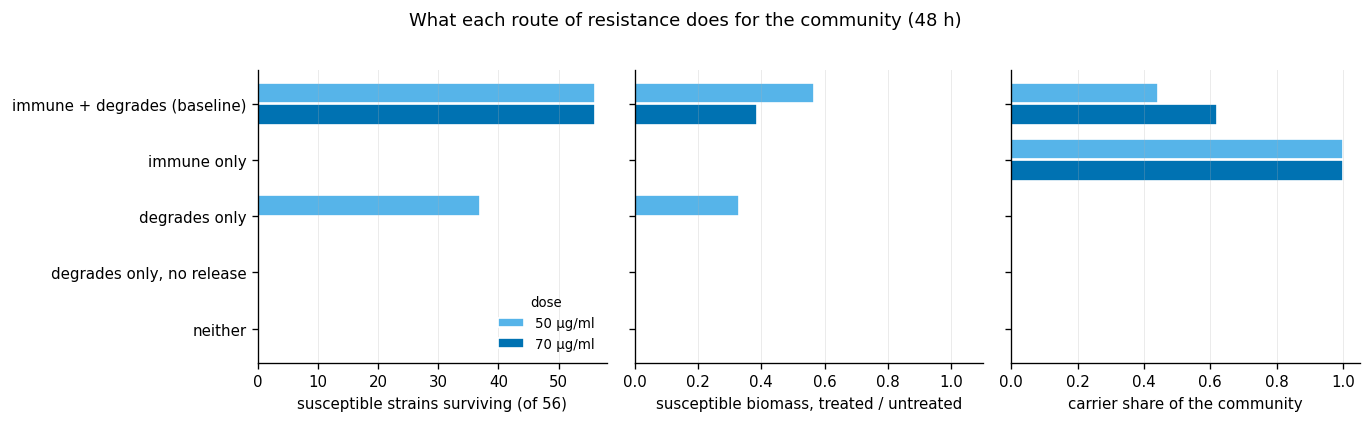

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.4), sharey=True)
names = list(SCENARIOS)
y = np.arange(len(names))
for ax, (col, label, lim) in zip(axs, [
        ("protected_richness", "susceptible strains surviving (of 56)", (0, 58)),
        ("protected_biomass_ratio", "susceptible biomass, treated / untreated", (0, 1.1)),
        ("resistant_share", "carrier share of the community", (0, 1.05))]):
    for k, (dose, color) in enumerate(zip(DOSES, [SKY, BLUE])):
        d = dissection[dissection.dose == dose].set_index("scenario").loc[names]
        ax.barh(y + (k - .5) * 0.38, d[col].fillna(0), height=0.36, color=color,
                label=f"{dose:g} µg/ml", edgecolor="white", linewidth=1)
    ax.set_xlim(*lim); ax.set_xlabel(label); ax.grid(axis="y", visible=False)
axs[0].set_yticks(y); axs[0].set_yticklabels(names); axs[0].invert_yaxis()
axs[0].legend(frameon=False, fontsize=8, loc="lower right", title="dose", title_fontsize=8)
fig.suptitle("What each route of resistance does for the community (48 h)", y=1.02)
fig.tight_layout(); save(fig, "01_dissection"); plt.show()

### Inside the treatment: drug, carrier and susceptible biomass over time

The same five carrier types at 50 µg/ml. Drug concentration is on a linear scale; biomass is on a log scale because the susceptible strains span many orders of magnitude.

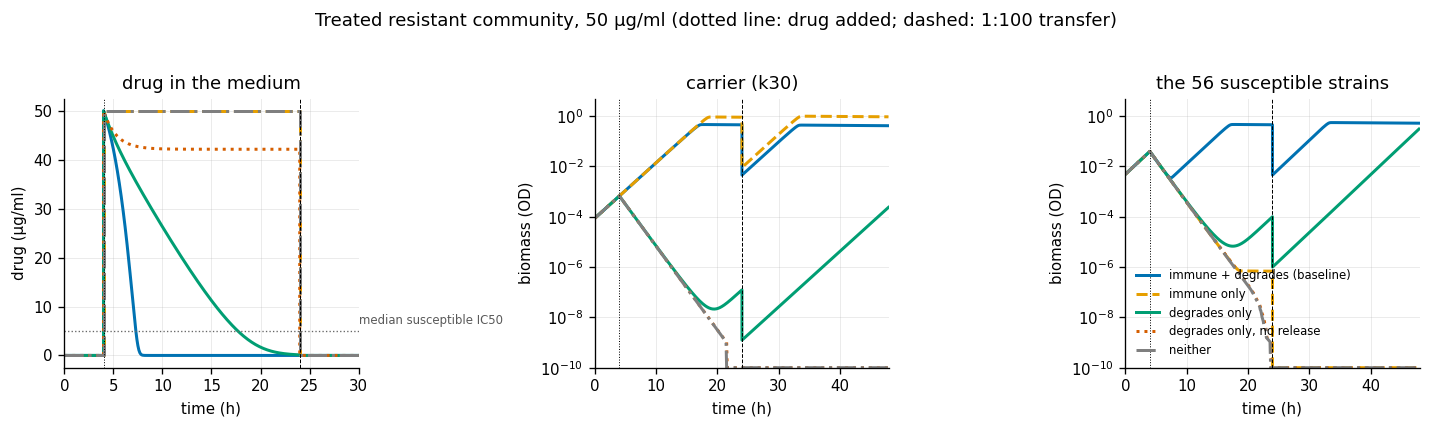

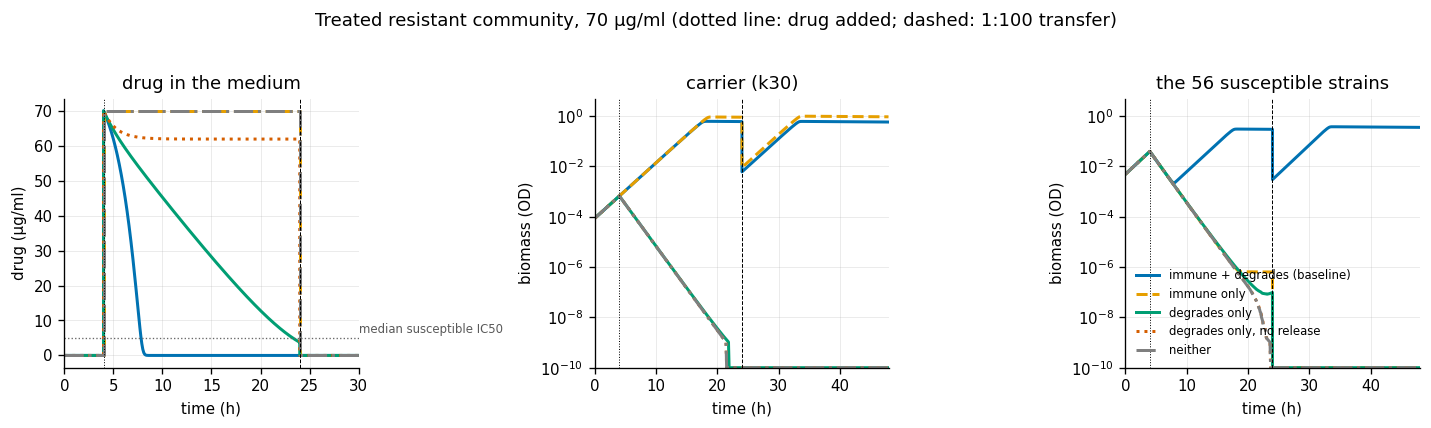

In [4]:
def timecourse_figure(dose, name):
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
    for scen, changes in SCENARIOS.items():
        sim = run(dose=dose, **changes).treated
        t, N, car = sim["t"], sim["N"], sim["carrier"]
        kw = dict(color=SCEN_COLORS[scen], ls=SCEN_STYLE[scen], lw=1.8, label=scen)
        axs[0].plot(t, sim["a"], **kw)
        axs[1].plot(t, np.maximum(N[:, car].sum(1), 1e-10), **kw)
        axs[2].plot(t, np.maximum(N[:, ~car].sum(1), 1e-10), **kw)
    axs[0].axhline(BASELINE.susceptible_ic50, color="0.4", lw=.8, ls=":")
    axs[0].annotate("median susceptible IC50", (30, BASELINE.susceptible_ic50 + 1.5),
                    fontsize=7, color="0.35")
    axs[0].set(ylabel="drug (µg/ml)", xlim=(0, 30), title="drug in the medium")
    axs[1].set(yscale="log", ylim=(1e-10, 5), ylabel="biomass (OD)", title="carrier (k30)")
    axs[2].set(yscale="log", ylim=(1e-10, 5), ylabel="biomass (OD)",
               title="the 56 susceptible strains")
    for ax in axs:
        ax.axvline(BASELINE.pregrowth_h, color="k", lw=.6, ls=":")
        ax.axvline(BASELINE.pregrowth_h + BASELINE.treatment_h, color="k", lw=.6, ls="--")
        ax.set_xlabel("time (h)")
    axs[1].set_xlim(0, 48); axs[2].set_xlim(0, 48)
    axs[2].legend(fontsize=7, frameon=False, loc="lower left")
    fig.suptitle(f"Treated resistant community, {dose:g} µg/ml "
                 "(dotted line: drug added; dashed: 1:100 transfer)", y=1.03)
    fig.tight_layout(); save(fig, name); plt.show()

timecourse_figure(50.0, "02_timecourses_50")
timecourse_figure(70.0, "02_timecourses_70")

### What the dissection shows

- **Immunity alone protects no one.** With an immune carrier that does not degrade the drug, all 56 susceptible strains go extinct at both doses and the carrier inherits the entire community (share 1.0). This is the same as the all-sensitive community, plus a winner.
- **Degradation without immunity protects partially, and only at the lower dose.** At 50 µg/ml, 37 of 56 survive (19 go extinct); at 70 µg/ml, none. The carrier itself is driven down to about 10⁻⁸ OD and the drug takes 13.7 h to clear, against 3.3 h with an immune degrader.
- **In that case, nearly all the rescue comes from enzyme released by dying carriers.** Remove the release (`free_enzyme_activity = 0`) and the drug plateaus around 42 µg/ml: the carriers die within hours, having removed only about 8 µg/ml while alive, and nobody survives.
- **"Neither" reproduces the all-sensitive community**, as it should.

**Interpretation.** Protection of the other strains is a *public good* (drug removal), but its supply depends on a *private good* (immunity) that keeps the producer alive long enough to clear the drug. Neither route alone gives the baseline's complete rescue. This sharpens the model's existing check 12 ("degradation, not the survival of a resistant strain, rescues the community"): degradation is necessary, and immunity is what makes it sufficient at the lab's doses.

## 2. Partial private protection

Between immune (`carrier_lysis = 0`) and fully susceptible (`= 1`) lies partial protection: the carrier dies more slowly than its neighbours but still dies. This is Ma et al.'s $\beta$ between 0 and 1, and a reasonable stand-in for the checklist's "partial resistance" item. Swept on a fine grid at three doses.

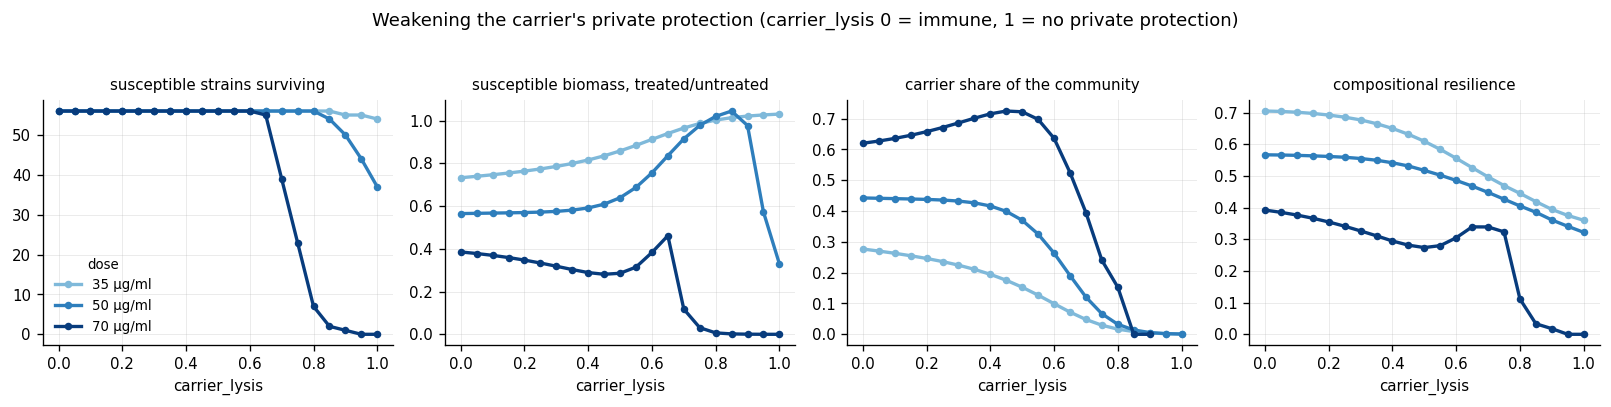

Per dose, the carrier_lysis that keeps all 56 susceptible strains with the smallest carrier share:
 dose  carrier_lysis  resistant_share  protected_biomass_ratio  compositional_resilience  drug_clearance_h
 35.0           0.85            0.009                    1.013                     0.419               8.2
 50.0           0.80            0.032                    1.019                     0.405              11.4
 70.0           0.00            0.620                    0.385                     0.392               3.9


In [5]:
LYSIS = np.round(np.linspace(0, 1, 21), 3)
PART_DOSES = [35.0, 50.0, 70.0]
partial = pd.concat([sweep("carrier_lysis", LYSIS, dose=d).assign(dose=d) for d in PART_DOSES],
                    ignore_index=True)
partial.to_csv(OUT / "partial_private_protection.csv", index=False)

dose_colors = dict(zip(PART_DOSES, plt.cm.Blues([0.45, 0.7, 0.95])))
fig, axs = plt.subplots(1, 4, figsize=(13.5, 3.2))
for ax, (col, label) in zip(axs, [
        ("protected_richness", "susceptible strains surviving"),
        ("protected_biomass_ratio", "susceptible biomass, treated/untreated"),
        ("resistant_share", "carrier share of the community"),
        ("compositional_resilience", "compositional resilience")]):
    for d in PART_DOSES:
        s = partial[partial.dose == d]
        ax.plot(s.carrier_lysis, s[col], "-o", ms=3.5, color=dose_colors[d], label=f"{d:g} µg/ml")
    ax.set_xlabel("carrier_lysis")
    ax.set_title(label, fontsize=9)
axs[0].legend(frameon=False, fontsize=8, title="dose", title_fontsize=8)
fig.suptitle("Weakening the carrier's private protection "
             "(carrier_lysis 0 = immune, 1 = no private protection)", y=1.04)
fig.tight_layout(); save(fig, "03_partial_private_protection"); plt.show()

best = (partial[partial.protected_richness == 56]
        .sort_values("resistant_share").groupby("dose").head(1))
print("Per dose, the carrier_lysis that keeps all 56 susceptible strains "
      "with the smallest carrier share:")
print(best[["dose", "carrier_lysis", "resistant_share", "protected_biomass_ratio",
            "compositional_resilience", "drug_clearance_h"]].round(3).to_string(index=False))

### What partial protection shows

- **At 35 and 50 µg/ml there is a sweet spot.** Up to `carrier_lysis ≈ 0.8` every susceptible strain survives, while the carrier's eventual share falls from 0.44 to about 0.03 (50 µg/ml) and susceptible biomass fully recovers (treated/untreated ≈ 1.0, up from 0.57). A carrier that is only partly protected still clears the drug, but cannot then take over.
- **At 70 µg/ml the sweet spot disappears.** Strains start to be lost from `carrier_lysis ≈ 0.65`, and only full immunity keeps all 56.
- **Less takeover is not the same as recovering the original composition.** Compositional resilience *falls* as private protection weakens, even as the carrier's share drops. Clearance takes longer (3.3 h → 11.4 h at the 50 µg/ml sweet spot), so the drug acts on the susceptible strains for longer and reshapes them, favouring the more tolerant ones. Keeping strains alive and keeping their relative abundances are two different outcomes.

## 3. Private protection × public degradation

The full plane: how much private protection (`carrier_lysis`) against how much public good (`vmax`, live-cell degradation per OD of carrier). Dose 50 µg/ml, released-enzyme activity at its default.

### Which values of `vmax` are physically possible?

`vmax` is not measured, so before sweeping it we bound it from enzyme kinetics. Order-of-magnitude inputs:

| Quantity | Value | Source |
|---|---|---|
| TEM-1 amount in *E. coli* carrying pUC19 | 1–2 % of total cell protein | attributed to Rinas & Bailey 1993 for JM101(pUC19); not verified against the full text, so treat as an assumption |
| Total protein per cell | ≈ 0.16 pg | textbook *E. coli* value |
| → TEM-1 molecules per cell (29 kDa) | ≈ 3 × 10⁴ – 7 × 10⁴ | |
| TEM-1 turnover of carbenicillin, $k_{cat}$ | ≈ 100 s⁻¹ (relative $V_m$ ≈ 10 % of penicillin G, whose $k_{cat}$ ≈ 1 160 s⁻¹) | Choury et al. 1999 (K<sub>m</sub> 14 µM, relative V<sub>m</sub>); Caniça et al. 1998 (penicillin G k<sub>cat</sub>) |
| Cells per OD | 10⁹ /ml | the model's `cells_per_OD` |
| Carbenicillin | 1 µM ≈ 0.378 µg/ml | MW 378 |

Then, per OD of carrier,

$$v_{\max} pprox rac{5	imes10^{4}\ 	ext{enzymes} 	imes 10^{9}\ 	ext{cells/ml}}{6.0	imes10^{23}} 	imes 100\ 	ext{s}^{-1} 	imes 3600\ 	ext{s/h} 	imes 0.378 pprox 1	imes10^{4}\ \mu	ext{g/ml/h/OD}.$$

This is a **ceiling**: it assumes every enzyme molecule works at full speed with unlimited substrate access. In intact cells the outer membrane slows carbenicillin's entry into the periplasm, so the true whole-cell rate is likely several-fold lower. Allowing for the uncertainty in each input (about 2× in expression, 2× in $k_{cat}$), the ceiling is about **3 × 10⁴**, and a realistic intact-cell range is roughly **10² – 10⁴**.

So the model's default (`vmax = 10 000`) already sits **at the ceiling**, and values above 3 × 10⁴ are not physically attainable for this strain. The sweep below therefore stops at 3 × 10⁴; the row at 3 × 10⁴ is marked as the upper bound. (An earlier version of this notebook went to 10⁵; that row has been removed.)


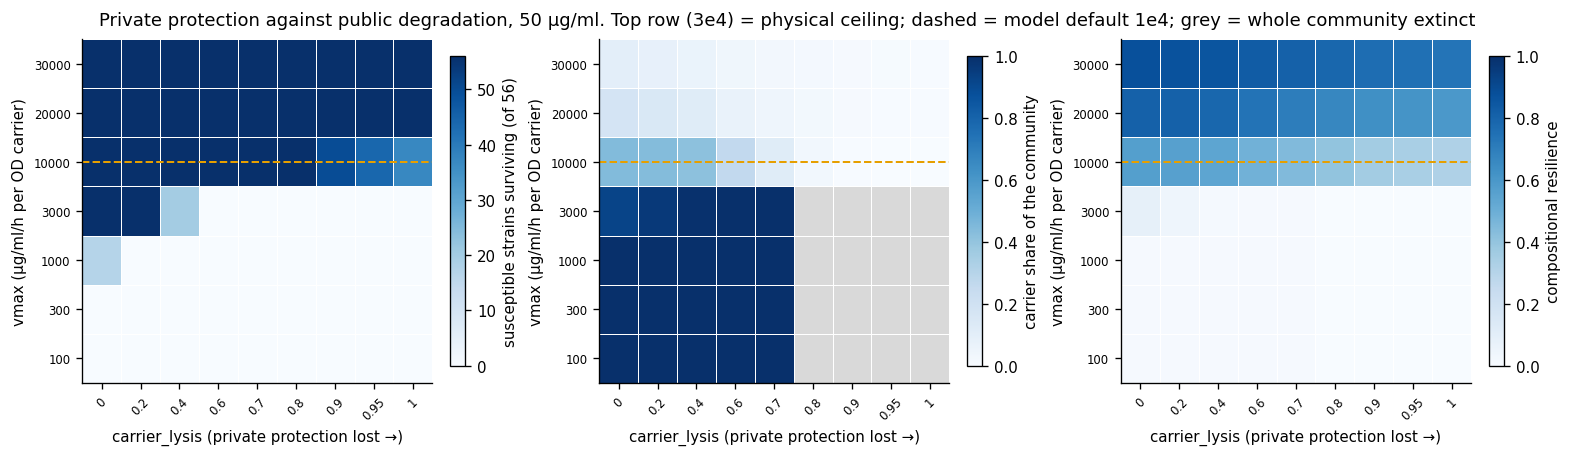

In [6]:
VMAX = [100, 300, 1000, 3000, 10000, 20000, 30000]   # 3e4 = physical ceiling (see above)
LYS2 = [0.0, 0.2, 0.4, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]
plane = grid("carrier_lysis", LYS2, "vmax", VMAX)
plane.to_csv(OUT / "lysis_x_vmax.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
for ax, (col, label, kw) in zip(axs, [
        ("protected_richness", "susceptible strains surviving (of 56)", dict(vmin=0, vmax=56)),
        ("resistant_share", "carrier share of the community", dict(vmin=0, vmax=1)),
        ("compositional_resilience", "compositional resilience", dict(vmin=0, vmax=1))]):
    im = heatmap(ax, plane, "carrier_lysis", "vmax", col, **kw)
    ax.set_xlabel("carrier_lysis (private protection lost →)")
    ax.set_ylabel("vmax (µg/ml/h per OD carrier)")
    ax.axhline(VMAX.index(10000) + .5, color=ORANGE, lw=1.2, ls="--")   # model default
    fig.colorbar(im, ax=ax, shrink=.9, label=label)
fig.suptitle("Private protection against public degradation, 50 µg/ml. Top row (3e4) = physical ceiling; "
             "dashed = model default 1e4; grey = whole community extinct")
save(fig, "04_lysis_x_vmax"); plt.show()

### What the plane shows

- **Rescue needs degradation close to its physical ceiling.** Within the plausible range (`vmax` ≤ 3 × 10⁴), an immune carrier rescues all 56 strains only from `vmax` ≈ 3 000 upward; at 1 000 it saves 17, and at 300 or below nothing. The model's default of 10 000 is at the estimated kinetic ceiling, and a realistic intact-cell rate (outer-membrane-limited, likely several-fold lower) would put the baseline near the edge of the rescue region. Either k30's whole-cell activity really is close to its maximum, or the model is missing something else that helps the community (for example, more carrier biomass at drug addition than assumed).
- **Near the ceiling, private and public protection substitute for each other.** At `vmax` = 2 × 10⁴ or 3 × 10⁴, all strains survive at every `carrier_lysis`. At 10 000, strains are lost only above `carrier_lysis` 0.8; at 3 000, only a nearly immune carrier (≤ 0.2) rescues everyone.
- **Compositional resilience tracks degradation speed:** 0.57 at the default, 0.81 at 2 × 10⁴ and 0.88 at 3 × 10⁴ for an immune carrier, because faster clearance shortens the drug's action on the susceptible strains.
- **The carrier-share panel shows the cost of immunity.** In the rescue region, immune carriers end up as much of the community (share 0.44 at the default); non-immune ones stay rare.

**Measurement that would settle this:** carbenicillin clearance by a known OD of k30 alone in each medium (bioassay or nitrocefin), which gives `vmax` directly and tells us how close to the ceiling the strain operates.


## 4. The released-enzyme route

When carriers are not immune, they die, and their enzyme spills into the medium. How much does this "public good released by death" matter? Swept over its activity, at full and partial loss of immunity, and over how quickly free enzyme is inactivated.

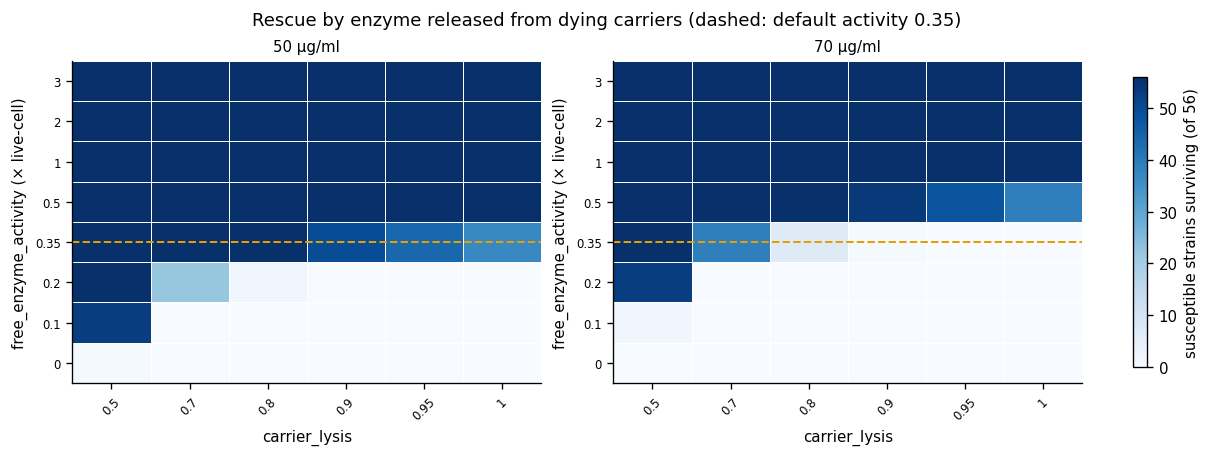

Degrades-only carrier: effect of free-enzyme inactivation (50 µg/ml)
 free_enzyme_activity  enzyme_decay  protected_richness  protected_biomass_ratio  drug_clearance_h
                 0.35          0.00                  37                    0.330              13.7
                 0.35          0.03                   8                    0.019              16.9
                 0.35          0.10                   0                    0.000               NaN
                 0.35          0.30                   0                    0.000               NaN
                 0.35          1.00                   0                    0.000               NaN
                 0.35          2.00                   0                    0.000               NaN
                 1.00          0.00                  56                    1.005               5.7
                 1.00          0.03                  56                    1.006               6.0
                 1.00          0.10     

In [7]:
FREE = [0.0, 0.1, 0.2, 0.35, 0.5, 1.0, 2.0, 3.0]   # free activity x vmax <= the 3e4 ceiling
LYS3 = [0.5, 0.7, 0.8, 0.9, 0.95, 1.0]
release = pd.concat([grid("carrier_lysis", LYS3, "free_enzyme_activity", FREE, dose=d).assign(dose=d)
                     for d in DOSES], ignore_index=True)
release.to_csv(OUT / "lysis_x_free_enzyme.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
for ax, d in zip(axs, DOSES):
    im = heatmap(ax, release[release.dose == d], "carrier_lysis", "free_enzyme_activity",
                 "protected_richness", vmin=0, vmax=56)
    ax.set_xlabel("carrier_lysis"); ax.set_ylabel("free_enzyme_activity (× live-cell)")
    ax.set_title(f"{d:g} µg/ml", fontsize=9)
    # mark Ma et al.'s default activity
    ax.axhline(FREE.index(0.35) + .5, color=ORANGE, lw=1.2, ls="--")
fig.colorbar(im, ax=axs, shrink=.9, label="susceptible strains surviving (of 56)")
fig.suptitle("Rescue by enzyme released from dying carriers (dashed: default activity 0.35)")
save(fig, "05_lysis_x_free_enzyme"); plt.show()

decay = pd.concat([sweep("enzyme_decay", [0, 0.03, 0.1, 0.3, 1.0, 2.0], carrier_lysis=1.0,
                         free_enzyme_activity=a).assign(free_enzyme_activity=a)
                   for a in (0.35, 1.0)], ignore_index=True)
decay.to_csv(OUT / "enzyme_decay.csv", index=False)
print("Degrades-only carrier: effect of free-enzyme inactivation (50 µg/ml)")
print(decay[["free_enzyme_activity", "enzyme_decay", "protected_richness",
             "protected_biomass_ratio", "drug_clearance_h"]].round(3).to_string(index=False))

### What the released-enzyme route shows

- **It can fully replace immunity, but only if the released enzyme is active enough.** For a fully non-immune carrier, all 56 strains survive at 50 µg/ml once `free_enzyme_activity` ≥ 0.5, and at 70 µg/ml once it is ≥ 1. At Ma et al.'s default (0.35) the rescue is partial (37 of 56) at 50 µg/ml and absent at 70.
- **Partial immunity lowers the activity needed.** A carrier with `carrier_lysis = 0.5` needs only a little release (activity 0.1–0.2) to rescue nearly everyone at 50 µg/ml, because it survives longer and keeps degrading. With no release at all, even it fails (1 survivor).
- **The route is fragile to enzyme inactivation.** At the default activity, even slow decay (0.03 /h, a half-life of about 23 h) cuts survivors from 37 to 8, and 0.1 /h removes the rescue. At activity 1 the rescue tolerates decay up to 0.1 /h and fails by 0.3 /h.

Both quantities are measurable: β-lactamase activity in culture supernatant (for example by nitrocefin hydrolysis) and how quickly it decays after the carriers are removed.

## 5. Dose response of each route

From 5 to 500 µg/ml. "Partial (0.8)" is the partial-protection carrier from section 2.

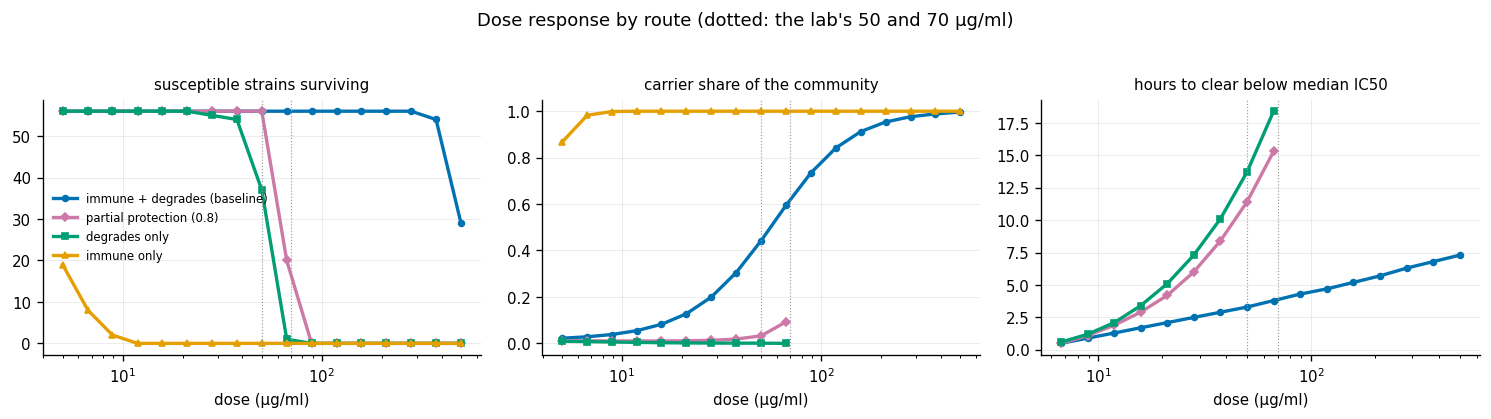

Highest dose at which all 56 susceptible strains survive:
route
degrades only                    21.1
immune + degrades (baseline)    281.2
immune only                       NaN
partial protection (0.8)         50.0


In [8]:
DOSE_GRID = np.round(np.logspace(np.log10(5), np.log10(500), 17), 1)
ROUTES = {"immune + degrades (baseline)": {}, "partial protection (0.8)": dict(carrier_lysis=0.8),
          "degrades only": dict(carrier_lysis=1.0), "immune only": dict(vmax=0.0)}
ROUTE_COLORS = dict(zip(ROUTES, [BLUE, PURPLE, GREEN, ORANGE]))
ROUTE_MARK = dict(zip(ROUTES, ["o", "D", "s", "^"]))
doser = pd.concat([sweep("dose", DOSE_GRID, **c).assign(route=r) for r, c in ROUTES.items()],
                  ignore_index=True)
doser.to_csv(OUT / "dose_response_by_route.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.3))
for ax, (col, label) in zip(axs, [("protected_richness", "susceptible strains surviving"),
                                  ("resistant_share", "carrier share of the community"),
                                  ("drug_clearance_h", "hours to clear below median IC50")]):
    for r in ROUTES:
        s = doser[doser.route == r]
        ax.plot(s.dose, s[col], marker=ROUTE_MARK[r], ms=3.5, color=ROUTE_COLORS[r], label=r)
    for d in DOSES:
        ax.axvline(d, color="0.6", lw=.7, ls=":")
    ax.set(xscale="log", xlabel="dose (µg/ml)"); ax.set_title(label, fontsize=9)
axs[0].legend(frameon=False, fontsize=7)
fig.suptitle("Dose response by route (dotted: the lab's 50 and 70 µg/ml)", y=1.04)
fig.tight_layout(); save(fig, "06_dose_response_by_route"); plt.show()

def last_full_rescue(s):
    ok = s[s.protected_richness == 56]
    return ok.dose.max() if len(ok) else np.nan
print("Highest dose at which all 56 susceptible strains survive:")
print(doser.groupby("route").apply(last_full_rescue, include_groups=False).rename("dose").to_string())

### What the dose responses show

- **The immune degrader rescues everyone up to about 280 µg/ml**, the partially protected carrier (0.8) up to 50 µg/ml, and the non-immune degrader only up to about 21 µg/ml. The lab's two doses, 50 and 70 µg/ml, sit exactly where the routes diverge, so the 50-versus-70 comparison is informative about mechanism.
- **Clearance time rises much faster with dose when the carrier is not immune.** Each extra µg/ml has to be removed by a producer population that is itself being killed.
- **An immune non-degrading carrier never helps.** The few strains surviving at the lowest doses do so anyway: at 5 µg/ml the all-sensitive community keeps the same 19 strains, and at 6.6–8.8 µg/ml it keeps *more* (14) than the community with an immune carrier (8 and 2), because the immune carrier takes their space. (Its 24 h protection score is still positive, about 3–4 log2 units, because competition with the carrier slows everyone's growth and therefore their killing. The 48 h richness is the more reliable readout here.)

## 6. Can more carriers make up for no immunity?

Without immunity, each carrier is killed, so each contributes degradation only briefly. Does spreading resistance over more strains compensate? Nested carrier sets from the model's default ordering (k30 first).

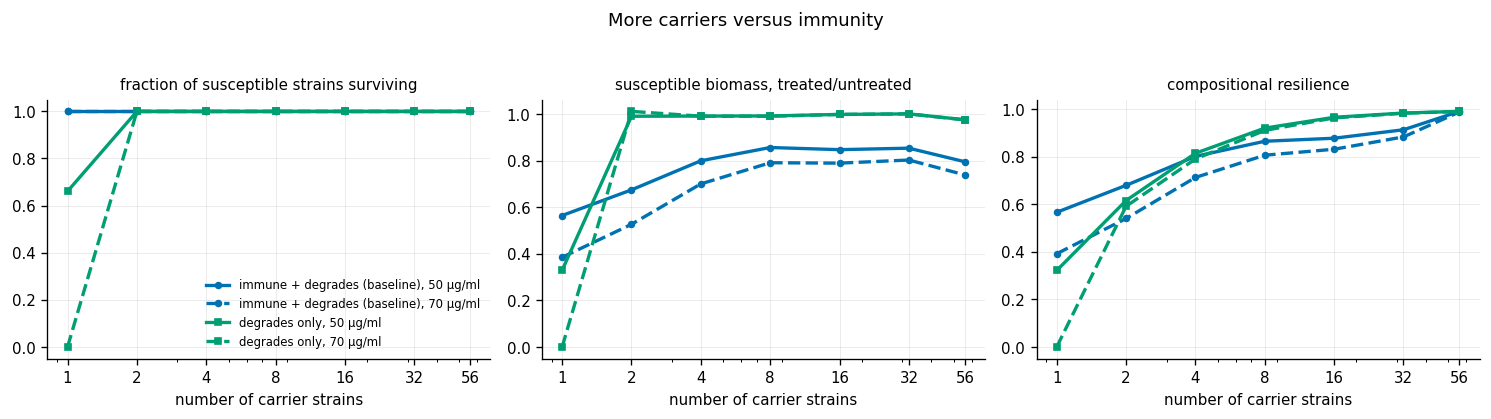

In [9]:
NRES = [1, 2, 4, 8, 16, 32, 56]
morecar = pd.concat([sweep("n_resistant", NRES, dose=d, **c).assign(route=r, dose=d)
                     for r, c in [("immune + degrades (baseline)", {}),
                                  ("degrades only", dict(carrier_lysis=1.0))]
                     for d in DOSES], ignore_index=True)
morecar.to_csv(OUT / "carriers_vs_immunity.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.3))
for ax, (col, label) in zip(axs, [
        ("protected_richness", "susceptible strains surviving"),
        ("protected_biomass_ratio", "susceptible biomass, treated/untreated"),
        ("compositional_resilience", "compositional resilience")]):
    for r, color, mk in [("immune + degrades (baseline)", BLUE, "o"), ("degrades only", GREEN, "s")]:
        for d, ls in zip(DOSES, ["-", "--"]):
            s = morecar[(morecar.route == r) & (morecar.dose == d)]
            y = s[col] if col != "protected_richness" else s[col] / (57 - s.n_resistant)
            ax.plot(s.n_resistant, y, ls=ls, marker=mk, ms=3.5, color=color,
                    label=f"{r}, {d:g} µg/ml")
    ax.set(xscale="log", xlabel="number of carrier strains")
    ax.set_xticks(NRES); ax.set_xticklabels(NRES)
    ax.set_title(label if col != "protected_richness"
                 else "fraction of susceptible strains surviving", fontsize=9)
axs[0].legend(frameon=False, fontsize=7)
fig.suptitle("More carriers versus immunity", y=1.04)
fig.tight_layout(); save(fig, "07_carriers_vs_immunity"); plt.show()

### What spreading resistance shows

- **Two non-immune degraders already rescue every strain**, at both doses, and with more carriers they do *better* than the baseline on the community-level readouts. Susceptible biomass recovers fully (≈ 1.0, against 0.5–0.86 for immune carriers), and compositional resilience exceeds the baseline from 4 carriers on, because non-immune carriers cannot take over.
- **Caveat: which strains carry the gene matters for non-immune carriers.** In the default nested order the second carrier is k47, which grows slightly faster than k30 (0.558 vs. 0.539 /h after cost) and has a higher IC50 (6.6 vs. 2.8 µg/ml). Section 7 suggests the carrier's growth rate is the trait that matters most for a non-immune degrader.

## 7. Robustness across trait draws

Every result above uses one draw of strain growth rates and IC50s (`seed = 42`). Here the five carrier types are repeated over 12 independent draws.

Across 12 trait draws:
                                   survivors_median  survivors_min  survivors_max  carrier_share_median  full_rescue_seeds
dose scenario                                                                                                             
50.0 immune + degrades (baseline)              56.0             56             56                 0.375                 12
     immune only                                0.0              0              0                 1.000                  0
     degrades only                             25.0              3             54                 0.000                  0
     degrades only, no release                  0.0              0              1                 0.000                  0
     neither                                    0.0              0              0                   NaN                  0
70.0 immune + degrades (baseline)              56.0             56             56                 0.561             

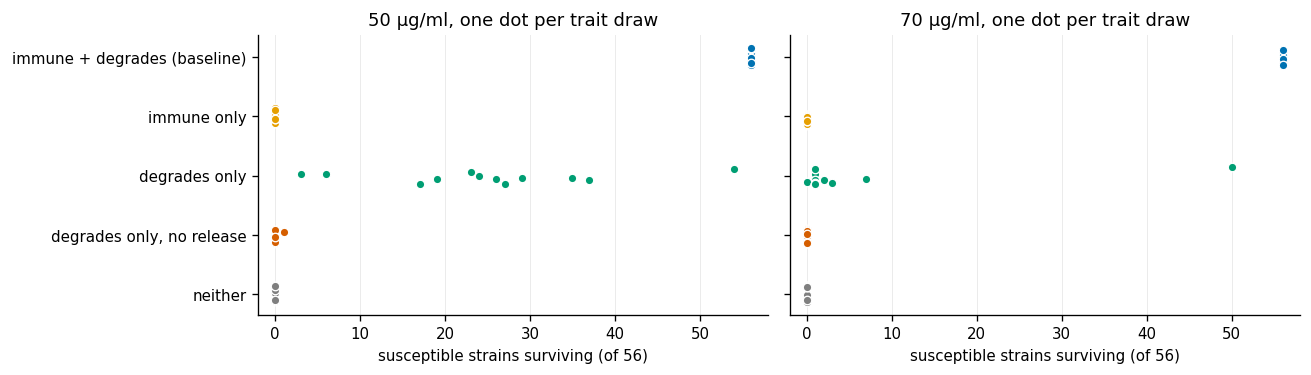

In [10]:
SEEDS = [1, 2, 3, 5, 7, 11, 13, 17, 23, 42, 99, 123]
rob = pd.DataFrame([{"seed": s, "dose": d, "scenario": n,
                     **run(seed=s, dose=d, **c).metrics[KEY].to_dict()}
                    for s in SEEDS for d in DOSES for n, c in SCENARIOS.items()])
rob.to_csv(OUT / "seed_robustness.csv", index=False)

summary = (rob.groupby(["dose", "scenario"], sort=False)
           .agg(survivors_median=("protected_richness", "median"),
                survivors_min=("protected_richness", "min"),
                survivors_max=("protected_richness", "max"),
                carrier_share_median=("resistant_share", "median"),
                full_rescue_seeds=("protected_richness", lambda v: int((v == 56).sum()))))
print(f"Across {len(SEEDS)} trait draws:")
print(summary.round(3).to_string())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
rng = np.random.default_rng(0)
for ax, d in zip(axs, DOSES):
    for k, n in enumerate(SCENARIOS):
        v = rob[(rob.dose == d) & (rob.scenario == n)].protected_richness
        ax.scatter(v, k + rng.uniform(-.15, .15, v.size), s=26, color=SCEN_COLORS[n],
                   edgecolor="white", linewidth=.8, zorder=3)
    ax.set_yticks(range(len(SCENARIOS))); ax.set_yticklabels(list(SCENARIOS))
    ax.set(xlim=(-2, 58), xlabel="susceptible strains surviving (of 56)",
           title=f"{d:g} µg/ml, one dot per trait draw")
    ax.grid(axis="y", visible=False)
axs[0].invert_yaxis()
fig.tight_layout(); save(fig, "08_seed_robustness"); plt.show()

### What the trait draws show

- **The immune-degrader rescue is robust**: all 56 strains survive in all 12 draws at both doses. Immune-only and "neither" fail in every draw.
- **The non-immune-degrader result is not robust.** At 50 µg/ml it ranges from 3 to 54 survivors (median 25), and at 70 µg/ml from 0 to 50 (median 1). Seed 42, used everywhere above, gives 37, which is above the median.

Why does it vary so much? The plot below compares k30's own drawn traits with the outcome. This is exploratory: 12 points, no claim of a fitted relationship.

 seed  k30_ic50  k30_ic50_rank  k30_growth  k30_growth_rank  survivors_degrades_only_50
   17     5.694             41       0.441               57                           3
    2     2.076              9       0.462               56                           6
    5     1.693              8       0.514               39                          17
    7     3.882             33       0.526               37                          19
  123     1.950              8       0.521               45                          23
   99     9.237             52       0.517               50                          24
   13     1.916             10       0.535               41                          26
    3     2.235             14       0.564               20                          27
   11     3.167             17       0.522               41                          29
    1     2.500             15       0.530               40                          35
   42     2.818             18  

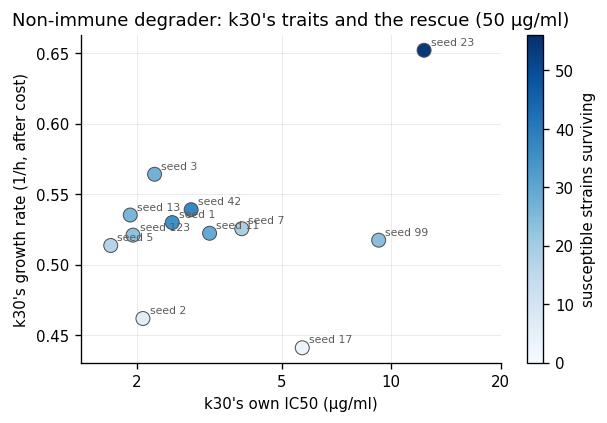

In [11]:
from dataclasses import replace
from scipy.stats import spearmanr
from resilience_model import community

traits = []
for sd in SEEDS:
    mu, ic50, carrier, n0 = community(replace(BASELINE, seed=sd))
    k = BASELINE.focal_index
    survivors = rob[(rob.seed == sd) & (rob.dose == 50.0) &
                    (rob.scenario == "degrades only")].protected_richness.iloc[0]
    traits.append(dict(seed=sd, k30_ic50=ic50[k], k30_ic50_rank=int((ic50 < ic50[k]).sum()) + 1,
                       k30_growth=mu[k], k30_growth_rank=int((mu > mu[k]).sum()) + 1,
                       survivors_degrades_only_50=survivors))
traits = pd.DataFrame(traits).sort_values("survivors_degrades_only_50")
traits.to_csv(OUT / "k30_traits_vs_degrades_only.csv", index=False)
print(traits.round(3).to_string(index=False))
for col in ("k30_ic50", "k30_growth"):
    rho, pval = spearmanr(traits[col], traits.survivors_degrades_only_50)
    print(f"Spearman rho, {col} vs survivors: {rho:.2f} (n = {len(traits)}, p = {pval:.2f})")

fig, ax = plt.subplots(figsize=(5.2, 3.6))
sc = ax.scatter(traits.k30_ic50, traits.k30_growth, c=traits.survivors_degrades_only_50,
                cmap="Blues", vmin=0, vmax=56, s=70, edgecolor="0.3", linewidth=.6, zorder=3)
for _, r in traits.iterrows():
    ax.annotate(f"seed {int(r.seed)}", (r.k30_ic50, r.k30_growth), fontsize=6.5,
                xytext=(4, 3), textcoords="offset points", color="0.35")
ax.set(xscale="log", xlim=(1.4, 20), xlabel="k30's own IC50 (µg/ml)", ylabel="k30's growth rate (1/h, after cost)",
       title="Non-immune degrader: k30's traits and the rescue (50 µg/ml)")
ax.set_xticks([2, 5, 10, 20]); ax.set_xticklabels(["2", "5", "10", "20"])
ax.minorticks_off()
fig.colorbar(sc, ax=ax, label="susceptible strains surviving")
fig.tight_layout(); save(fig, "09_k30_traits_degrades_only"); plt.show()

**k30's growth rate tracks the outcome closely; its IC50 does not** (Spearman ρ ≈ 0.86 for growth and 0.27 for IC50, printed above). The draw where k30 is the fastest grower (seed 23) gives 54 survivors, and the one where it is the slowest (seed 17) gives 3, even though k30 is fairly tolerant in both. A likely reason: a faster-growing carrier has more biomass, and therefore more enzyme, when the drug arrives at 4 h, and more enzyme to release when it lyses. This is 12 draws, and the rest of the community changes between draws too, so treat it as a strong hint rather than an established relationship.

## Summary

| Carrier type | 50 µg/ml | 70 µg/ml | Takes over? | Robust across draws? |
|---|---|---|---|---|
| Immune + degrades (baseline) | 56/56 survive | 56/56 | yes (share 0.44 / 0.62) | yes, 12/12 |
| Partial protection (`carrier_lysis = 0.8`) | 56/56 | 7/56 | no (share 0.03) | not tested |
| Degrades only | 37/56 | 0/56 | no | no (3–54 survivors at 50) |
| Immune only | 0/56 | 0/56 | completely | yes (always fails) |
| Neither | 0/56 | 0/56 | — | — |

**Main conclusions**

1. **Degradation is the protective act; immunity is what keeps it going.** Immunity without degradation never helps the others and can hurt them. Degradation without immunity helps only at lower doses, and then mostly through enzyme released by the dying carrier.
2. **There is a trade-off between protecting and taking over.** The immune carrier that protects most robustly is also the one that ends up dominating. A partly protected carrier can rescue everyone with almost no takeover at 35–50 µg/ml, but that window closes at 70 µg/ml.
3. **The 50 vs. 70 µg/ml comparison discriminates mechanism.** Mechanisms that agree at 50 µg/ml (baseline, partial protection) separate at 70.
4. **Distributing non-immune degradation across a few strains** gives the best community-level recovery in the model. How well a non-immune carrier protects depends strongly on its own growth rate.

**Experiments these suggest**

- *Degradation without immunity:* add purified TEM-1, or sterile supernatant from a k30 culture, to the all-sensitive community at matched activity. This removes immunity entirely and tests whether drug removal alone rescues the community.
- *Immunity without degradation:* a carrier resistant through a non-degrading mechanism (for example reduced permeability), at a matched MIC.
- *Released enzyme:* measure supernatant β-lactamase activity during treatment and its decay afterwards; these set `free_enzyme_activity` and `enzyme_decay`, which the non-immune results depend on strongly.

**Limits.** `vmax` is not measured; the default (10 000 µg/ml/h/OD) is at the kinetic ceiling estimated in section 3, so the baseline protection may be optimistic. Deterministic and well mixed: no spatial structure (where private protection matters most) and no replicate noise. Carriers have no IC50 of their own when immune; partial protection is a constant fraction (Ma et al.'s β), not a dose-dependent shift in the carrier's IC50. Results for non-immune carriers depend on the trait draw.